In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
df = pd.read_csv("../data/city_day.csv")

print("Shape:", df.shape)
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Data types:
City              str
Date              str
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket        str
dtype: object

Missing values:
City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64


In [3]:
# Convert Date from text to an actual datetime type
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Date coverage
print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())
print("Invalid dates:", df["Date"].isna().sum())

# City coverage
print("\nNumber of unique cities:", df["City"].nunique())
print("\nObservations per city:")
display(df["City"].value_counts())

# Exact duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# Missing AQI and category on the same rows?
print("\nBoth AQI and AQI_Bucket missing:",
      (df["AQI"].isna() & df["AQI_Bucket"].isna()).sum())

# Numerical summaries
display(df.describe().T)

Earliest date: 2015-01-01 00:00:00
Latest date: 2020-07-01 00:00:00
Invalid dates: 0

Number of unique cities: 26

Observations per city:


City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ernakulam              162
Kochi                  162
Aizawl                 113
Name: count, dtype: int64


Exact duplicate rows: 0

Both AQI and AQI_Bucket missing: 4681


,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


In [12]:
print("\nData types:")
print(df.dtypes)


Data types:
City                     str
Date          datetime64[us]
PM2.5                float64
PM10                 float64
NO                   float64
NO2                  float64
NOx                  float64
NH3                  float64
CO                   float64
SO2                  float64
O3                   float64
Benzene              float64
Toluene              float64
Xylene               float64
AQI                  float64
AQI_Bucket               str
dtype: object


In [5]:
# Summary statistics for numerical columns
display(df.describe().T.round(2))

,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


In [6]:
city_aqi = df.groupby("City").agg(
    total_rows=("AQI", "size"),
    valid_aqi=("AQI", "count"),
    mean_aqi=("AQI", "mean"),
    median_aqi=("AQI", "median")
)

city_aqi["aqi_missing_pct"] = (
    100 * (1 - city_aqi["valid_aqi"] / city_aqi["total_rows"])
)

display(
    city_aqi.sort_values("valid_aqi", ascending=False).round(2)
)

,total_rows,valid_aqi,mean_aqi,median_aqi,aqi_missing_pct
City,,,,,
Delhi,2009,1999,259.49,257.0,0.50
Bengaluru,2009,1910,94.32,86.0,4.93
Lucknow,2009,1893,217.97,198.0,5.77
Chennai,2009,1884,114.50,100.0,6.22
Hyderabad,2006,1880,109.21,104.0,6.28
Patna,1858,1459,240.78,215.0,21.47
Gurugram,1679,1453,225.12,208.0,13.46
Ahmedabad,2009,1334,452.12,384.5,33.60
Visakhapatnam,1462,1171,117.27,106.0,19.90


In [7]:
print(
    "Repeated city-date records:",
    df.duplicated(subset=["City", "Date"]).sum()
)

Repeated city-date records: 0


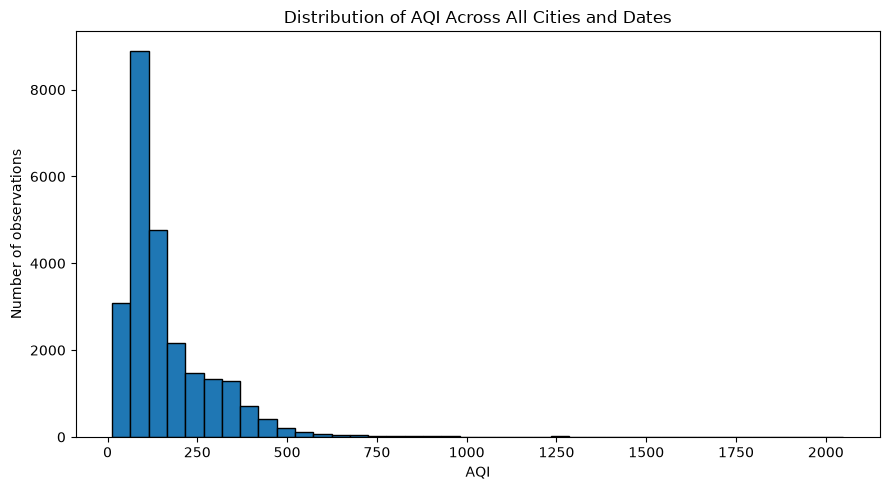

In [8]:
aqi_values = df["AQI"].dropna()

plt.figure(figsize=(9, 5))
plt.hist(aqi_values, bins=40, edgecolor="black")

plt.xlabel("AQI")
plt.ylabel("Number of observations")
plt.title("Distribution of AQI Across All Cities and Dates")
plt.tight_layout()
plt.show()

In [9]:
# Create a summary of missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

# Show columns with missing values, sorted by percentage
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

display(missing_summary)


,Missing_Count,Missing_Percentage
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62


In [10]:

# Calculate the percentage of missing values in each city
missing_by_city = (
    df.groupby("City")
      .apply(lambda city: city.isnull().mean() * 100, include_groups=False)
)

# Focus on AQI and important pollutant measurements
cols = ["AQI", "PM2.5", "PM10", "NO2", "CO"]

display(missing_by_city[cols].round(1).sort_values("AQI", ascending=False))


,AQI,PM2.5,PM10,NO2,CO
City,,,,,
Mumbai,61.4,61.0,62.0,62.4,1.2
Jorapokhar,34.0,67.6,23.5,23.1,43.9
Shillong,33.9,20.6,22.3,19.0,10.6
Ahmedabad,33.6,31.3,79.7,30.3,30.3
Talcher,24.5,19.9,19.4,24.0,16.0
Brajrajnagar,24.0,19.7,18.4,24.9,16.0
Patna,21.5,17.3,89.7,11.0,8.1
Visakhapatnam,19.9,15.7,16.1,17.0,2.7
Gurugram,13.5,9.2,55.9,8.1,6.5


In [11]:

# Select numerical measurements
numeric_cols = df.select_dtypes(include="number").columns

# Count negative values in each numerical column
negative_counts = (df[numeric_cols] < 0).sum()

print("Negative values:")
display(negative_counts[negative_counts > 0])

# Inspect the lowest and highest values
print("Minimum and maximum values:")
display(df[numeric_cols].agg(["min", "max"]).T)

# Examine the largest AQI observations
print("10 highest AQI observations:")
display(
    df.nlargest(10, "AQI")[
        ["City", "Date", "AQI", "AQI_Bucket"]
    ]
)


Negative values:


Series([], dtype: int64)

Minimum and maximum values:


,min,max
PM2.5,0.04,949.99
PM10,0.01,1000.00
NO,0.02,390.68
NO2,0.01,362.21
NOx,0.00,467.63
NH3,0.01,352.89
CO,0.00,175.81
SO2,0.01,193.86
O3,0.01,257.73
Benzene,0.00,455.03


10 highest AQI observations:


,City,Date,AQI,AQI_Bucket
1145,Ahmedabad,2018-02-19,2049.0,Severe
1136,Ahmedabad,2018-02-10,1917.0,Severe
560,Ahmedabad,2016-07-14,1842.0,Severe
1048,Ahmedabad,2017-11-14,1747.0,Severe
1463,Ahmedabad,2019-01-03,1719.0,Severe
1417,Ahmedabad,2018-11-18,1672.0,Severe
1420,Ahmedabad,2018-11-21,1646.0,Severe
1407,Ahmedabad,2018-11-08,1630.0,Severe
1127,Ahmedabad,2018-02-01,1613.0,Severe
1746,Ahmedabad,2019-10-13,1595.0,Severe


In [13]:

# Preserve the original dataset
df_clean = df.copy()

# Standardize text formatting in city names
df_clean["City"] = df_clean["City"].str.strip()

# Remove exact duplicate rows, if any
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
removed = before - len(df_clean)

print("Rows before cleaning:", before)
print("Exact duplicates removed:", removed)
print("Rows after cleaning:", len(df_clean))

# Verify the date column
print("Date data type:", df_clean["Date"].dtype)
print("Missing city names:", df_clean["City"].isna().sum())


Rows before cleaning: 29531
Exact duplicates removed: 0
Rows after cleaning: 29531
Date data type: datetime64[us]
Missing city names: 0


In [18]:

# Keep df_clean intact; create a task-specific dataset
aqi_data = df_clean.dropna(subset=["AQI"]).copy()

print("Rows in working copy:", len(df_clean))
print("Rows with known AQI:", len(aqi_data))
print("Rows excluded because AQI is missing:",
      len(df_clean) - len(aqi_data))
print("Remaining missing pollutant values:")
display(aqi_data.isna().sum().sort_values(ascending=False))


Rows in working copy: 29531
Rows with known AQI: 24850
Rows excluded because AQI is missing: 4681
Remaining missing pollutant values:


Xylene        15372
PM10           7086
NH3            6536
Toluene        5826
Benzene        3535
NOx            1857
O3              807
PM2.5           678
SO2             605
CO              445
NO2             391
NO              387
Date              0
City              0
AQI               0
AQI_Bucket        0
dtype: int64

In [19]:

pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]

regression_data = aqi_data.dropna(
    subset=pollutants
).copy()

print("AQI-labelled rows:", len(aqi_data))
print("Complete pollutant rows:", len(regression_data))
print(
    "Rows retained: "
    f"{len(regression_data) / len(aqi_data) * 100:.1f}%"
    if len(aqi_data) else "No AQI-labelled rows"
)

display(regression_data[["AQI"] + pollutants].describe().T)


AQI-labelled rows: 24850
Complete pollutant rows: 6236
Rows retained: 25.1%


,count,mean,std,min,25%,50%,75%,max
AQI,6236.0,140.510103,92.738826,23.00,78.0000,112.000,166.0000,677.00
PM2.5,6236.0,61.327365,53.709682,2.00,27.9275,47.490,73.4425,639.19
PM10,6236.0,123.418321,85.791491,7.80,66.9700,103.010,150.7700,796.88
NO,6236.0,17.015191,20.037836,0.25,5.0800,10.060,19.3925,159.22
NO2,6236.0,31.708190,18.784041,0.17,15.9775,28.900,43.6325,140.17
NOx,6236.0,32.448956,27.388129,0.17,14.5475,24.285,39.6225,224.09
NH3,6236.0,20.737070,16.088215,0.12,10.3900,14.690,28.5450,166.70
CO,6236.0,0.984344,1.356161,0.00,0.4900,0.730,1.0600,16.23
SO2,6236.0,11.514426,7.166113,0.71,6.5575,9.875,14.4300,70.39
O3,6236.0,36.127691,19.553695,1.55,22.3575,32.540,45.5125,162.33


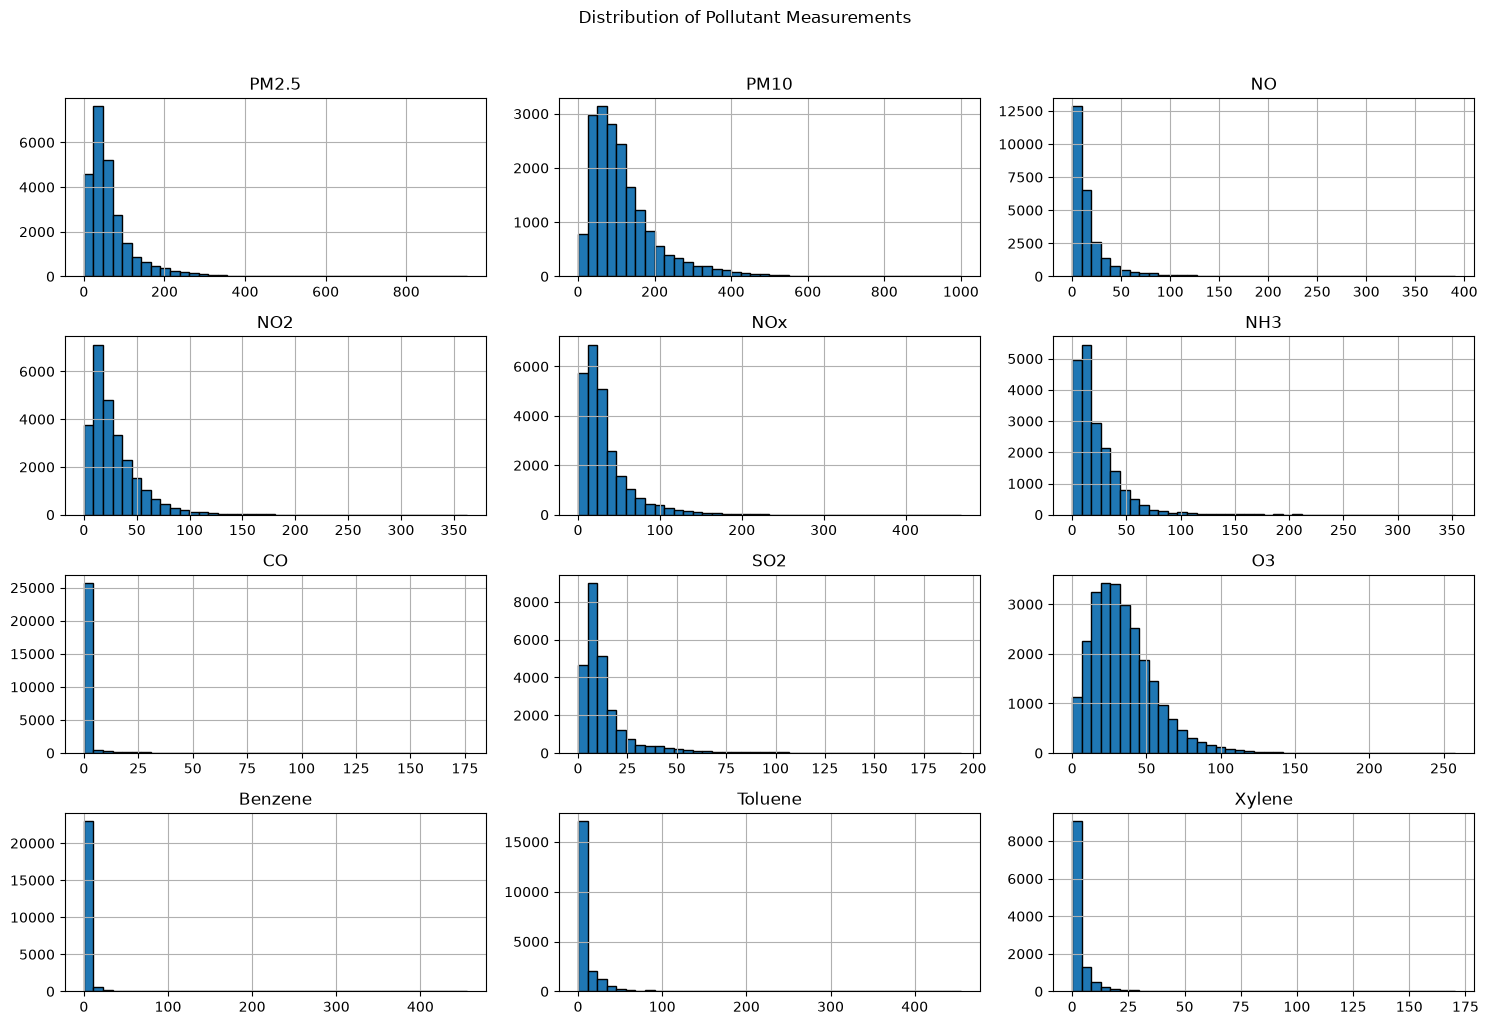

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns

pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]

df_clean[pollutants].hist(
    bins=40,
    figsize=(15, 10),
    layout=(4, 3),
    edgecolor="black"
)

plt.suptitle("Distribution of Pollutant Measurements", y=1.02)
plt.tight_layout()
plt.show()


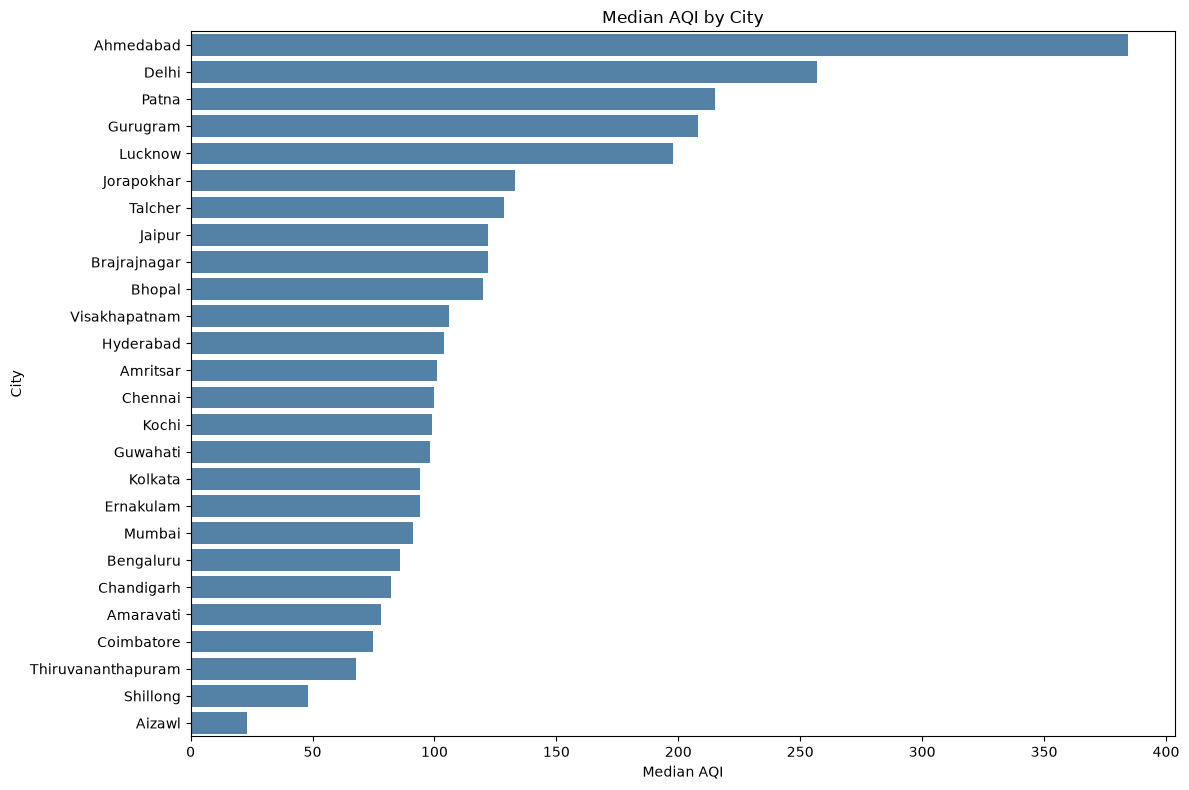

,median,mean,count
City,,,
Ahmedabad,384.5,452.122939,1334
Delhi,257.0,259.487744,1999
Patna,215.0,240.782042,1459
Gurugram,208.0,225.123882,1453
Lucknow,198.0,217.973059,1893
Jorapokhar,133.0,159.251621,771
Talcher,128.5,172.886819,698
Jaipur,122.0,133.679159,1094
Brajrajnagar,122.0,150.280505,713


In [21]:

city_aqi = (
    aqi_data.groupby("City")["AQI"]
    .agg(["median", "mean", "count"])
    .sort_values("median", ascending=False)
)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=city_aqi.reset_index(),
    x="median",
    y="City",
    color="steelblue"
)

plt.title("Median AQI by City")
plt.xlabel("Median AQI")
plt.ylabel("City")
plt.tight_layout()
plt.show()

display(city_aqi)


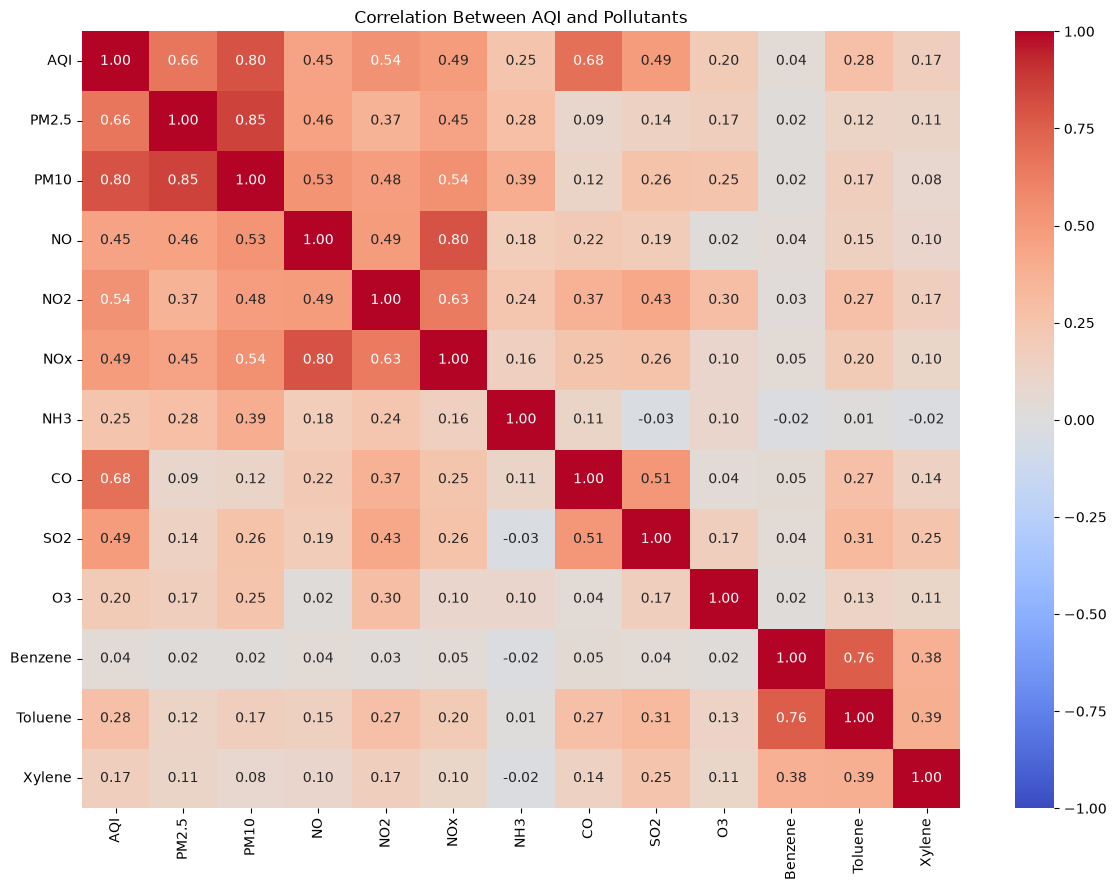

Pollutant correlations with AQI:


PM10       0.803313
CO         0.683346
PM2.5      0.659181
NO2        0.537071
SO2        0.490586
NOx        0.486450
NO         0.452191
Toluene    0.279992
NH3        0.252019
O3         0.198991
Xylene     0.165532
Benzene    0.044407
Name: AQI, dtype: float64

In [22]:

corr = aqi_data[["AQI"] + pollutants].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between AQI and Pollutants")
plt.tight_layout()
plt.show()

print("Pollutant correlations with AQI:")
display(
    corr["AQI"]
    .drop("AQI")
    .sort_values(key=abs, ascending=False)
)

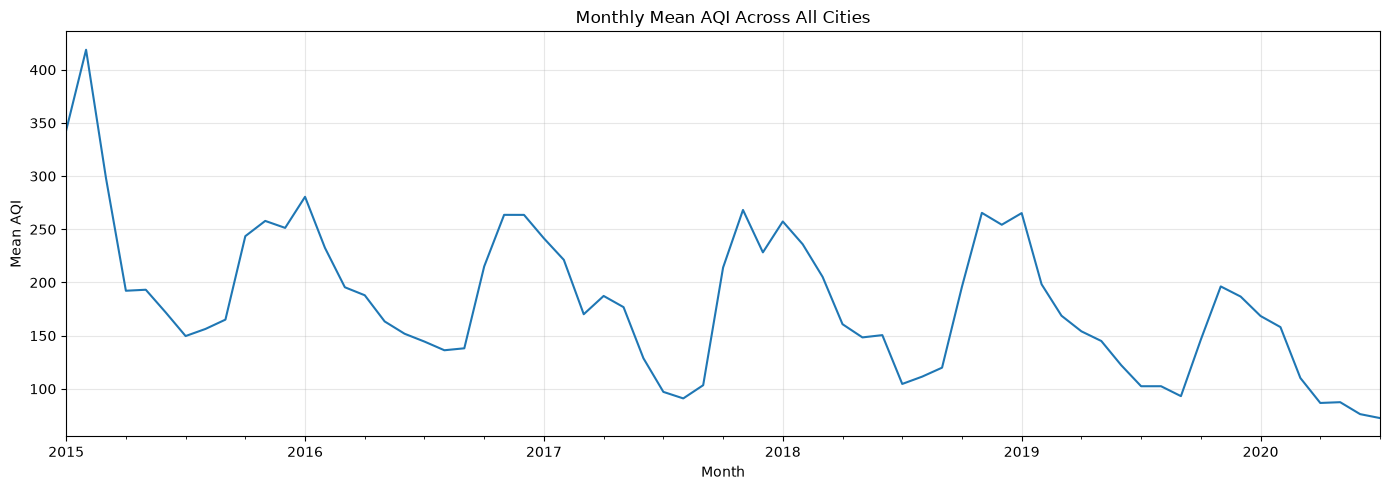

In [23]:

monthly_aqi = (
    aqi_data.assign(
        Month=aqi_data["Date"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("Month")["AQI"]
    .mean()
)

plt.figure(figsize=(14, 5))
monthly_aqi.plot()

plt.title("Monthly Mean AQI Across All Cities")
plt.xlabel("Month")
plt.ylabel("Mean AQI")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


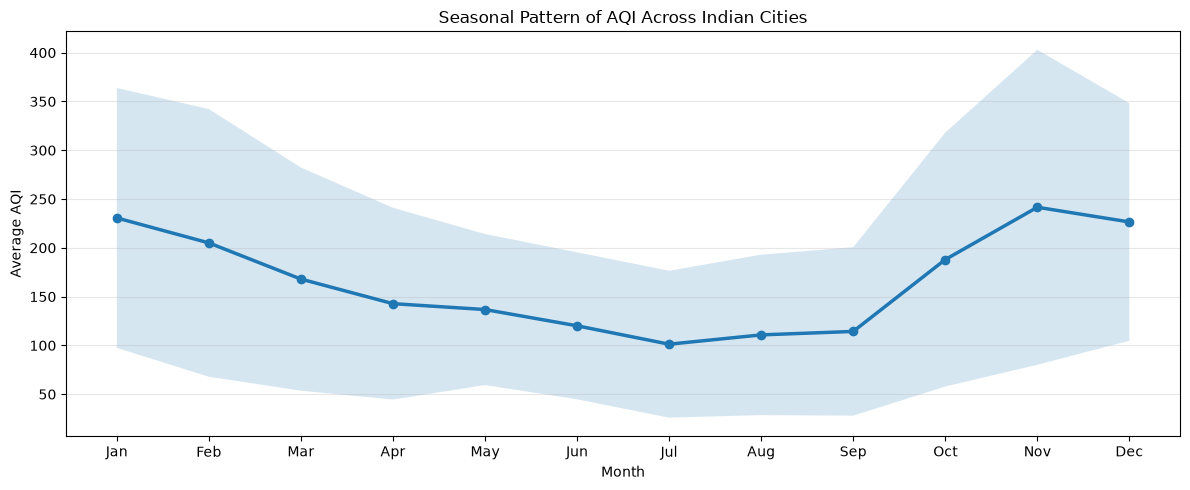

In [24]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Start with rows that have a known AQI
monthly_data = aqi_data.dropna(subset=["AQI"]).copy()

monthly_data["Year"] = monthly_data["Date"].dt.year
monthly_data["Month"] = monthly_data["Date"].dt.month

# First calculate monthly AQI for each city in each year
city_monthly = (
    monthly_data
    .groupby(["City", "Year", "Month"])["AQI"]
    .mean()
    .reset_index()
)

# Then average across cities and years for each calendar month
seasonal_aqi = (
    city_monthly
    .groupby("Month")["AQI"]
    .agg(["mean", "std", "count"])
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 5))

plt.plot(
    month_names,
    seasonal_aqi["mean"],
    marker="o",
    linewidth=2.5
)

plt.fill_between(
    month_names,
    seasonal_aqi["mean"] - seasonal_aqi["std"],
    seasonal_aqi["mean"] + seasonal_aqi["std"],
    alpha=0.18
)

plt.title("Seasonal Pattern of AQI Across Indian Cities")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


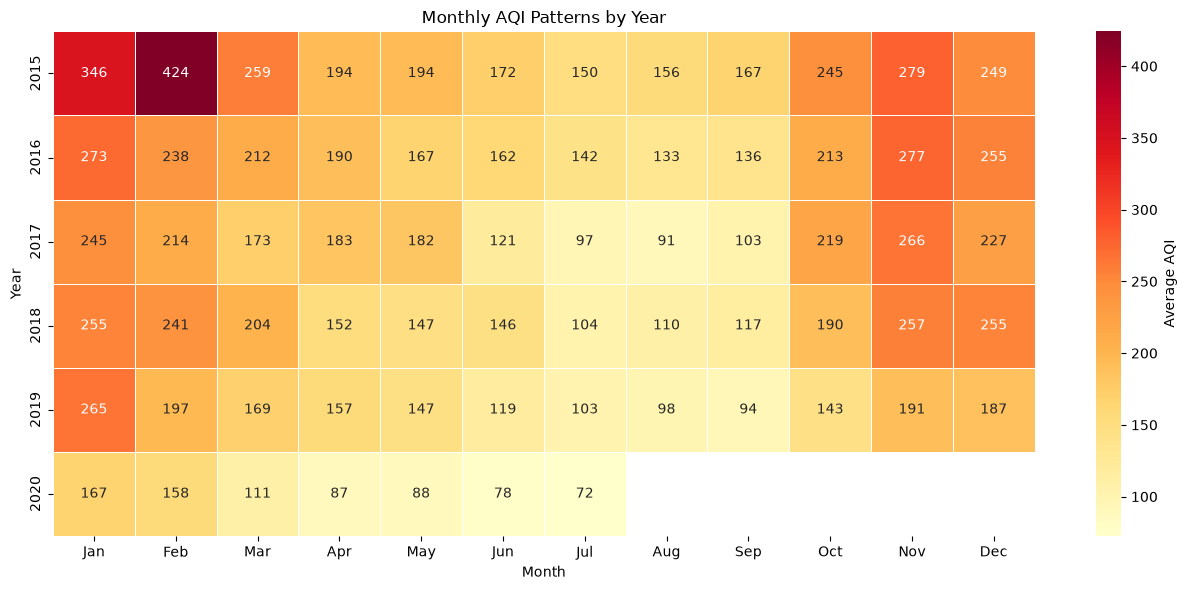

In [25]:

# Average each city-month within each year, then across cities
year_month_aqi = (
    city_monthly
    .groupby(["Year", "Month"])["AQI"]
    .mean()
    .reset_index()
)

heatmap_data = year_month_aqi.pivot(
    index="Year",
    columns="Month",
    values="AQI"
).reindex(columns=range(1, 13))

heatmap_data.columns = month_names

plt.figure(figsize=(13, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Average AQI"}
)

plt.title("Monthly AQI Patterns by Year")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()
